# 14 Follow-up on the long-scan candidates: why KMA missed 2019-04-15, and what group B is

Your reading of notebook 13 raised three questions, answered here with data:
1. **Group A (2019-04-15) looks real. Why is it not in the KMA catalog?**
   - How big the three events are, from their S amplitudes relative to the ML 1.9.
   - How often KMA cataloged swarm events of that size in 2025.
   - How KMA's magnitudes behave at that size.
2. **Group B is meaningful at JASA and occurs only from September 2023 to March 2025. What is it?**
   - Where the signal is seen: stacked envelopes at every station.
   - What it looks like at JASA: Haenam's station gather.
   - Whether the events repeat, and whether KMA cataloged anything there.
3. **Why did only template 400005 catch group B?** The weight each template gives to the JASA channels.

Amplitudes follow notebook 12: the 5–20 Hz peak ground displacement from 0.5 s before to 2.0 s after S, divided by the ML 1.9's amplitude on the same channel. Taking the ratio on the same channel cancels the instrument response. Only stations whose sensor epoch is unchanged from 2019 to 2025 are used for 2019.

In [1]:
import os, sys, glob, warnings
import numpy as np, pandas as pd
warnings.filterwarnings('ignore', message='Discarding nonzero nanoseconds')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'; FA = f'{DL}/fmf_aligned'
os.environ.update(FMF_RUN='imsil_5_20H_aligned_mad10_long', FMF_MAD_K='10', FMF_CC_FLOOR='0', FMF_BAND='5,20', FMF_STATION_LIST=f'{FA}/stations_imsil_5_20H_long.csv',
                  FMF_SEQUENCES='imsil', FMF_TEMPLATE_CSV='imsil_templates_ref25.csv', MAD_SEGMENTED='1', FMF_SNR_MIN='1.2', HELVETICA_DIR='/home/msseo/Download/Helvetica')
sys.path.insert(0, FA)
import config as C, similarity as S
import importlib.util
spec = importlib.util.spec_from_file_location('plotstyle', f'{DL}/pipeline/plotstyle.py'); plotstyle = importlib.util.module_from_spec(spec); spec.loader.exec_module(plotstyle)
import matplotlib.pyplot as plt
import obspy
from obspy import UTCDateTime
from obspy.geodetics import gps2dist_azimuth
from IPython.display import display, Image
FIG = f'{DL}/notebooks/figs_14'; os.makedirs(FIG, exist_ok=True)
long_cat = pd.read_csv(C.CATALOG_CSV, parse_dates=['origin'])
adopted = pd.read_csv(f'{DL}/catalogs/fmf_final/imsil_fmf_catalog.csv', parse_dates=['origin']).sort_values('origin').reset_index(drop=True)
kma24 = pd.read_csv(f'{DL}/catalogs/imsil_kma24.csv', parse_dates=['origin_time_UTC'])
kma_all = pd.read_csv('/home/msseo/works/72.2025_Imsil_swarm/data/catalogs/kma_entire_catalog_260309.csv', encoding='utf-8-sig'); kma_all['t'] = pd.to_datetime(kma_all.time) - pd.Timedelta(hours=9)
sta = pd.read_csv(f'{DL}/station_table/stations.csv').set_index('Code')
A = {'A1': '2019-04-15 14:17:35.472', 'A2': '2019-04-15 14:17:39.522', 'A3': '2019-04-15 14:43:15.432'}
Bt = long_cat[(long_cat.template_cuspid == 400005) & (long_cat.origin > '2023-01-01') & (long_cat.origin < '2025-10-01')].origin.sort_values().reset_index(drop=True)
print(f'group A: {len(A)} detections; group B: {len(Bt)} detections ({Bt.min():%Y-%m-%d} .. {Bt.max():%Y-%m-%d})')

group A: 3 detections; group B: 12 detections (2023-09-25 .. 2025-03-29)


## 1. Group A: how big, and how often KMA cataloged events of that size

**Amplitudes of the 2019 events.** The ML 1.9 (2025-11-02 20:38:35) is the reference. The stations are those whose sensor epoch is unchanged from 2019 to 2025, according to the master StationXML and the KMA RESP files checked on 2026-10-11. Channels count where the event's signal-to-noise ratio is ≥ 2 and the reference's is ≥ 20. The noise window is the 2.5 to 0.5 s before P.

In [2]:
picks = {}
for f in sorted(glob.glob(f'{DL}/runs/hypodd_dl/waveforms_100km/20251102203835/*.sac')):
    s = obspy.read(f, headonly=True)[0].stats; h = s.sac
    ref = UTCDateTime(year=h.nzyear, julday=h.nzjday, hour=h.nzhour, minute=h.nzmin, second=h.nzsec, microsecond=int(h.nzmsec) * 1000)
    d = picks.setdefault(s.station, dict(net=s.network, prefix=s.channel[:2], dist=float(h.dist)))
    if h.get('a', -12345) > -1e4: d['P'] = ref + float(h.a)
    if h.get('t0', -12345) > -1e4: d['S'] = ref + float(h.t0)
o_ref = UTCDateTime(adopted.origin[(adopted.origin - pd.Timestamp('2025-11-02 20:38:35.4')).abs().idxmin()].to_pydatetime())
def band_trace(net, stn, prefix, comp, t, band=(5, 20), disp=True, pre=60, post=100):
    f = glob.glob(f'{DL}/continuous/{net}/{stn}/{prefix}{comp}.D/*.D.{t.year}.{t.julday:03d}')
    if not f: return None
    st = obspy.read(f[0], starttime=t - pre, endtime=t + post)
    for x in st:
        x.data = x.data.astype(np.float64)
        if abs(x.stats.sampling_rate - 100.0) > 1e-6: x.detrend('linear'); x.resample(100.0)   # e.g. 100.0000076 Hz records (as notebook 12)
    st.merge(fill_value=0); tr = st[0]; tr.detrend('linear'); tr.taper(0.05); tr.filter('bandpass', freqmin=band[0], freqmax=band[1], corners=4, zerophase=True)
    if disp:
        for _ in range(2 if prefix == 'HG' else 1): tr.integrate(); tr.filter('bandpass', freqmin=band[0], freqmax=band[1], corners=4, zerophase=True)
    return tr
def peak(tr, a, b):
    w = tr.slice(a, b).data; return float(np.abs(w).max()) if len(w) else np.nan
STABLE = ['IMSB', 'JEU2', 'GKSA', 'CHOA', 'DGHA', 'WICA', 'SACA', 'PUAA', 'BAU', 'KCH2', 'SCHA', 'JASA']
rows = []
for stn in STABLE:
    v = picks.get(stn)
    if not v or 'S' not in v: continue
    for comp in 'ENZ':
        tr_r = band_trace(v['net'], stn, v['prefix'], comp, o_ref)
        if tr_r is None: continue
        ar, nr = peak(tr_r, v['S'] - 0.5, v['S'] + 2.0), peak(tr_r, v['P'] - 2.5, v['P'] - 0.5)
        for lab, t in A.items():
            o = UTCDateTime(t); tr = band_trace(v['net'], stn, v['prefix'], comp, o)
            if tr is None: continue
            a_, n_ = peak(tr, v['S'] + (o - o_ref) - 0.5, v['S'] + (o - o_ref) + 2.0), peak(tr, v['P'] + (o - o_ref) - 2.5, v['P'] + (o - o_ref) - 0.5)
            rows.append(dict(event=lab, station=stn, comp=comp, dist_km=v['dist'], ratio=a_ / ar, snr=a_ / n_, snr_ref=ar / nr))
AR = pd.DataFrame(rows); use = AR[(AR.snr >= 2) & (AR.snr_ref >= 20)]
AMP = use.groupby('event').agg(channels=('ratio', 'size'), median_log10_ratio=('ratio', lambda x: float(np.median(np.log10(x)))), stations=('station', lambda x: ', '.join(sorted(set(x)))))
AMP['ratio'] = 10 ** AMP.median_log10_ratio; AMP['ML_if_slope_1'] = 1.9 + AMP.median_log10_ratio
display(AMP.round(3))
print('A1 and A2 are 4.05 s apart; at IMSB A1\'s S falls inside A2\'s pre-P noise window, so IMSB drops out for A2.')

,channels,median_log10_ratio,stations,ratio,ML_if_slope_1
event,,,,,
A1,10,-1.599,"IMSB, JASA, JEU2, KCH2",0.025,0.301
A2,16,-1.362,"BAU, CHOA, DGHA, GKSA, JEU2, KCH2, WICA",0.043,0.538
A3,10,-1.613,"DGHA, GKSA, IMSB, JASA, JEU2, KCH2",0.024,0.287


A1 and A2 are 4.05 s apart; at IMSB A1's S falls inside A2's pre-P noise window, so IMSB drops out for A2.


**How often KMA cataloged swarm events of that size (2025).** The amplitude ratio of every swarm detection is the notebook 12 measurement E3: the median log ratio over the 8 channels on which the ML 1.9 has signal-to-noise ≥ 300 (JEU2 E/Z, MALA E/N/Z, NAWB E, SIDA E/N). It is recomputed here on the adopted catalog (235 detections). A detection counts as KMA-cataloged when a KMA origin lies within 3 s.

,detections,kma_cataloged,share
0.001-0.016,191,0,0.00
0.016-0.032,19,3,0.16
0.032-0.050,7,3,0.43
0.050-0.079,9,9,1.00
0.079-0.126,5,5,1.00
0.126-1.585,4,4,1.00


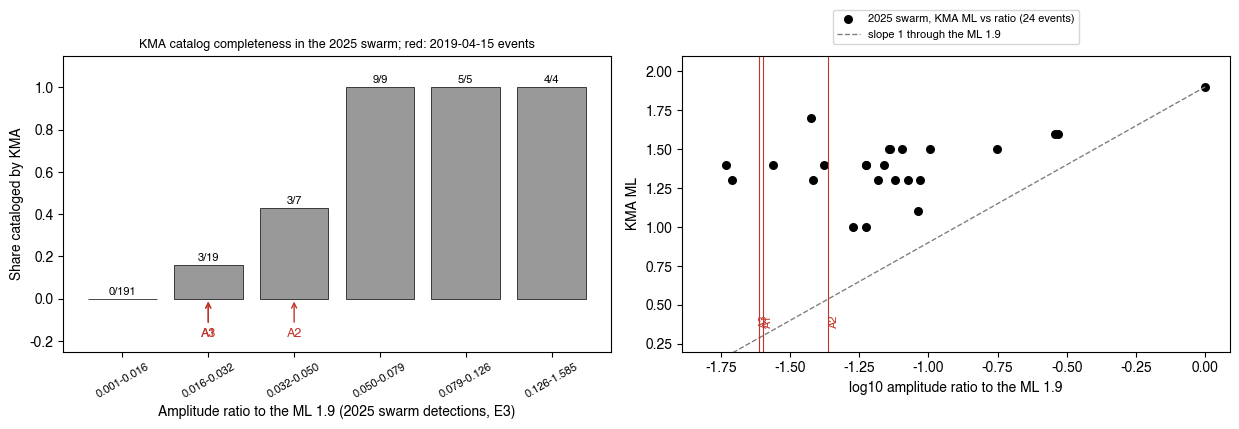

KMA catalog within 50 km of the swarm, 2016 - Oct 2025: 206 events; ML min 0.6, median 1.4; below ML 1.0: 7%
KMA ML of the 2025 swarm events with ratio <= 0.04: 0.019 -> ML 1.4, 0.020 -> ML 1.3, 0.027 -> ML 1.4, 0.038 -> ML 1.7, 0.038 -> ML 1.3


/home/msseo/miniforge3/envs/fmf/lib/python3.10/site-packages/obspy/geodetics/base.py:268: UserWarning: Catching unstable calculation on antipodes. The currently used Vincenty's Inverse formulae has known limitations for two nearly antipodal points. Install the Python module 'geographiclib' to solve this issue.
  warnings.warn(msg)


In [3]:
E3_CH = [('JEU2', 'E'), ('JEU2', 'Z'), ('MALA', 'E'), ('MALA', 'N'), ('MALA', 'Z'), ('NAWB', 'E'), ('SIDA', 'E'), ('SIDA', 'N')]
t_ev = [UTCDateTime(t.to_pydatetime()) for t in adopted.origin]; LR = []
def two_day_trace(net, stn, prefix, comp):
    # 2025-11-02 and -03 (the swarm spans both UTC days), processed as band_trace does
    st = obspy.Stream()
    for jd in (306, 307):
        for f in glob.glob(f'{DL}/continuous/{net}/{stn}/{prefix}{comp}.D/*.D.2025.{jd:03d}'): st += obspy.read(f)
    for x in st:
        x.data = x.data.astype(np.float64)
        if abs(x.stats.sampling_rate - 100.0) > 1e-6: x.detrend('linear'); x.resample(100.0)   # e.g. 100.0000076 Hz records (as notebook 12)
    st.merge(fill_value=0); tr = st[0]; tr.detrend('linear'); tr.taper(0.001); tr.filter('bandpass', freqmin=5, freqmax=20, corners=4, zerophase=True)
    for _ in range(2 if prefix == 'HG' else 1): tr.integrate(); tr.filter('bandpass', freqmin=5, freqmax=20, corners=4, zerophase=True)
    return tr
for stn, comp in E3_CH:
    v = picks[stn]; tr = two_day_trace(v['net'], stn, v['prefix'], comp)
    ar = peak(tr, v['S'] - 0.5, v['S'] + 2.0)
    LR.append([np.log10(peak(tr, v['S'] + (te - o_ref) - 0.5, v['S'] + (te - o_ref) + 2.0) / ar) for te in t_ev])
adopted['log10_ratio'] = np.nanmedian(np.array(LR), axis=0)
adopted['kma'] = [bool((kma24.origin_time_UTC - t).abs().min().total_seconds() <= 3) for t in adopted.origin]
bins = [-3, -1.8, -1.5, -1.3, -1.1, -0.9, 0.2]
adopted['bin'] = pd.cut(adopted.log10_ratio, bins)
rep = adopted.groupby('bin', observed=True).agg(detections=('kma', 'size'), kma_cataloged=('kma', 'sum')); rep['share'] = (rep.kma_cataloged / rep.detections).round(2)
rep.index = [f'{10 ** b.left:.3f}-{10 ** b.right:.3f}' for b in rep.index]; display(rep)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
mids = np.array([(a + b) / 2 for a, b in zip(bins[:-1], bins[1:])]); sh_ = rep.share.values
ax[0].bar(range(len(rep)), sh_, color='0.6', edgecolor='black', lw=0.5); ax[0].set_xticks(range(len(rep))); ax[0].set_xticklabels(rep.index, rotation=30, fontsize=8)
for i, (n, k) in enumerate(zip(rep.detections, rep.kma_cataloged)): ax[0].text(i, sh_[i] + 0.02, f'{k}/{n}', ha='center', fontsize=8)
for lab, r in AMP.iterrows():
    i = int(np.searchsorted(bins, r.median_log10_ratio) - 1); ax[0].annotate(lab, (i, 0.0), xytext=(i, -0.18), textcoords='data', ha='center', fontsize=9, color='#c1352b', arrowprops=dict(arrowstyle='->', color='#c1352b'))
ax[0].set_ylim(-0.25, 1.15); ax[0].set_ylabel('Share cataloged by KMA'); ax[0].set_xlabel('Amplitude ratio to the ML 1.9 (2025 swarm detections, E3)')
ax[0].set_title('KMA catalog completeness in the 2025 swarm; red: 2019-04-15 events', fontsize=9)
lr_k = np.array([adopted.log10_ratio[(adopted.origin - t).abs().idxmin()] for t in kma24.origin_time_UTC])
ax[1].scatter(lr_k, kma24.ML, s=30, color='black', label='2025 swarm, KMA ML vs ratio (24 events)')
xx = np.linspace(-1.8, 0, 50); ax[1].plot(xx, 1.9 + xx, color='0.5', ls='--', lw=1, label='slope 1 through the ML 1.9')
for lab, r in AMP.iterrows(): ax[1].axvline(r.median_log10_ratio, color='#c1352b', lw=0.8); ax[1].text(r.median_log10_ratio, 0.35, lab, color='#c1352b', fontsize=8, rotation=90, va='bottom')
ax[1].set_xlabel('log10 amplitude ratio to the ML 1.9'); ax[1].set_ylabel('KMA ML'); ax[1].set_ylim(0.2, 2.1)
ax[1].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=1, frameon=True, fontsize=8)
plt.tight_layout(); plt.show()
kd = gps2dist_azimuth; near = kma_all[[kd(35.5502, 127.2962, a, b)[0] / 1000 <= 50 for a, b in zip(kma_all.latitude, kma_all.longitude)]]
near = near[(near.t >= '2016-01-01') & (near.t < '2025-11-01')]
print(f'KMA catalog within 50 km of the swarm, 2016 - Oct 2025: {len(near)} events; ML min {near.magnitude.min()}, median {near.magnitude.median():.1f}; below ML 1.0: {(near.magnitude < 1.0).mean():.0%}')
print('KMA ML of the 2025 swarm events with ratio <= 0.04:', ', '.join(f'{r:.3f} -> ML {m}' for r, m in sorted(zip(10 ** lr_k, kma24.ML)) if r <= 0.04))

## 2. Group B: where the signal is seen, and what it looks like at JASA

**Stacked envelopes.** For every station, the 3-component 5–20 Hz envelope of each of the 12 detections is normalized by its own pre-event level (−20 to −5 s). The median over the 12 is then plotted against time from the detection origin. A real Imsil event would rise at IMSB (7 km) first and most. A source beside JASA rises at JASA only.

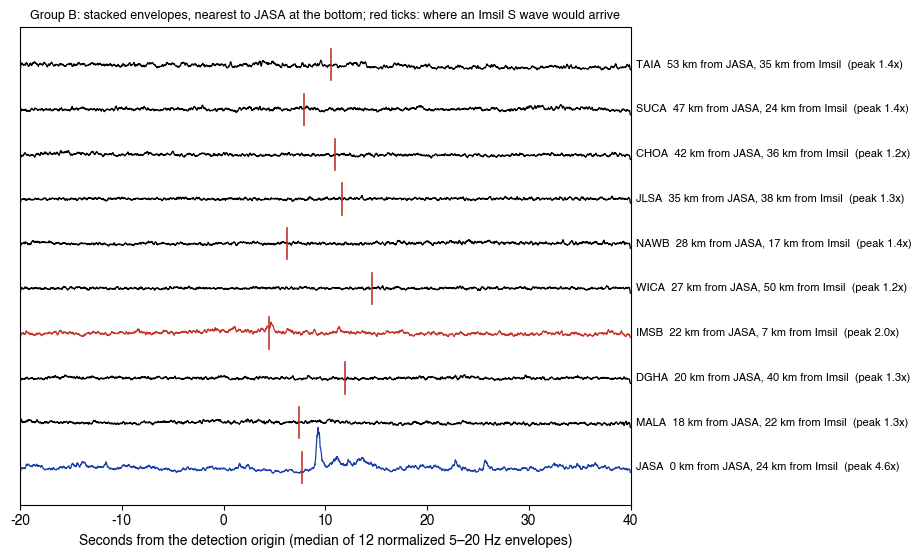

In [4]:
NEAR = ['JASA', 'MALA', 'DGHA', 'IMSB', 'WICA', 'NAWB', 'JLSA', 'CHOA', 'SUCA', 'TAIA']
tax = np.arange(-20, 40, 0.02); ENV = {}
for stn in NEAR:
    E = []
    for o in Bt:
        o = UTCDateTime(o.to_pydatetime()); es = []
        for comp in 'ENZ':
            tr = band_trace('KS', stn, picks.get(stn, {}).get('prefix', 'HG'), comp, o, disp=False, pre=40, post=60)
            if tr is None or abs(tr.stats.sampling_rate - 100) > 1e-6: continue
            i0 = int(round((o - 20 - tr.stats.starttime) * 100)); seg = tr.data[i0:i0 + len(tax) * 2:2]
            if len(seg) == len(tax): es.append(np.abs(seg))
        if not es: continue
        e = np.convolve(np.sqrt(np.mean(np.square(es), axis=0)), np.ones(10) / 10, 'same'); n0 = np.median(e[(tax > -20) & (tax < -5)])
        if n0 > 0: E.append(e / n0)
    if E: ENV[stn] = np.median(np.array(E), axis=0)
dJ = {s: gps2dist_azimuth(sta.Latitude['JASA'], sta.Longitude['JASA'], sta.Latitude[s], sta.Longitude[s])[0] / 1000 for s in ENV}
dI = {s: gps2dist_azimuth(35.5502, 127.2962, sta.Latitude[s], sta.Longitude[s])[0] / 1000 for s in ENV}
order = sorted(ENV, key=lambda s: dJ[s])
fig, ax = plt.subplots(figsize=(11, 6.2))
for k, s in enumerate(order):
    ax.plot(tax, k + 0.25 * (ENV[s] - 1), color='#1b3fa8' if s == 'JASA' else ('#c1352b' if s == 'IMSB' else 'black'), lw=0.9)
    ax.text(40.5, k, f'{s}  {dJ[s]:.0f} km from JASA, {dI[s]:.0f} km from Imsil  (peak {ENV[s][(tax > 0) & (tax < 35)].max():.1f}x)', fontsize=8, va='center')
    if s in picks and 'S' in picks[s]:
        ts = picks[s]['S'] - o_ref; ax.plot([ts, ts], [k - 0.35, k + 0.35], color='#c1352b', lw=1.2)
ax.set_yticks([]); ax.set_xlim(-20, 40); ax.set_xlabel('Seconds from the detection origin (median of 12 normalized 5–20 Hz envelopes)')
ax.set_title('Group B: stacked envelopes, nearest to JASA at the bottom; red ticks: where an Imsil S wave would arrive', fontsize=9)
plt.subplots_adjust(right=0.68); plt.show()

**At JASA, event by event.** The window runs from 5 to 14 s after the detection origin, 2–20 Hz velocity. For each event the table gives the time of the strongest 3-component arrival, of the vertical peak and of the horizontal peak, and the horizontal-to-vertical peak ratio. A distant S wave (an Imsil event at 24 km) arrives after a separate P (S − P ≈ 3 s at JASA) and is mainly horizontal. A source within a few kilometers gives one impulsive packet.

In [5]:
from obspy.signal.trigger import classic_sta_lta
W = {c: [] for c in 'ZNE'}; rowsB = []
for i, o in enumerate(Bt):
    o = UTCDateTime(o.to_pydatetime())
    for c in 'ZNE':
        tr = band_trace('KS', 'JASA', 'HG', c, o, band=(2, 20), disp=False, pre=40, post=60); tr.integrate(); tr.filter('bandpass', freqmin=2, freqmax=20, corners=4, zerophase=True)
        W[c].append(tr.slice(o + 2, o + 16).data[:1400].copy())
    z, n, e = (W[c][-1] for c in 'ZNE'); h = np.hypot(n, e); t = np.arange(len(z)) / 100 + 2
    cft = classic_sta_lta(np.sqrt(z ** 2 + h ** 2), 20, 200)
    rowsB.append(dict(event=f'B{i + 1}', origin_UTC=f'{pd.Timestamp(Bt[i]):%Y-%m-%d %H:%M:%S}', KST=f'{pd.Timestamp(Bt[i]) + pd.Timedelta(hours=9):%H:%M}',
                      strongest_arrival_s=t[np.argmax(cft)], vertical_peak_s=t[np.argmax(np.abs(z))], horizontal_peak_s=t[np.argmax(h)], H_over_V=h.max() / np.abs(z).max()))
JB = pd.DataFrame(rowsB); display(JB.round(2))
imsb_sp = picks['JASA']['S'] - picks['JASA']['P']
print(f'for comparison: the ML 1.9 (an Imsil event) at JASA: S - P = {imsb_sp:.2f} s')
def maxcc(a, b, L=100):
    a = a - a.mean(); out = -1
    for l in range(-L, L + 1):
        bb = np.roll(b, l); bb = bb - bb.mean(); out = max(out, float((a * bb).sum() / np.sqrt((a * a).sum() * (bb * bb).sum())))
    return out
nB = len(Bt); M = np.full((nB, nB), np.nan)
for i in range(nB):
    for j in range(i + 1, nB):
        M[i, j] = M[j, i] = np.mean([maxcc(W[c][i][550:1050], W[c][j][550:1050]) for c in 'NE'])
iu = np.triu_indices(nB, 1)
print(f'inter-event similarity at JASA (N/E, 7.5-12.5 s, +-1 s lag): median {np.nanmedian(M[iu]):.2f}, range {np.nanmin(M[iu]):.2f}-{np.nanmax(M[iu]):.2f} (repeating earthquakes typically > 0.9)')

,event,origin_UTC,KST,strongest_arrival_s,vertical_peak_s,horizontal_peak_s,H_over_V
0,B1,2023-09-25 08:46:01,17:46,9.22,9.33,9.55,1.55
1,B2,2023-10-09 12:59:28,21:59,9.35,13.35,9.34,1.54
2,B3,2024-01-11 07:08:56,16:08,9.25,9.34,9.36,1.56
3,B4,2024-01-16 03:17:52,12:17,5.87,15.61,9.35,1.33
4,B5,2024-02-12 03:06:37,12:06,10.93,14.40,13.09,1.82
5,B6,2024-02-20 21:37:43,06:37,9.34,11.32,9.33,1.42
6,B7,2024-02-26 03:02:25,12:02,9.37,2.00,9.49,1.11
7,B8,2024-03-01 05:33:34,14:33,9.35,9.35,9.50,1.12
8,B9,2024-04-08 05:40:36,14:40,9.24,14.23,14.69,1.26
9,B10,2024-05-19 03:05:47,12:05,9.35,12.61,12.64,1.13


for comparison: the ML 1.9 (an Imsil event) at JASA: S - P = 3.15 s


inter-event similarity at JASA (N/E, 7.5-12.5 s, +-1 s lag): median 0.39, range 0.25-0.76 (repeating earthquakes typically > 0.9)


12 detections x 3 components at KS.JASA -> /home/msseo/works/72.2025_Imsil_swarm/DL_detection/notebooks/figs_14/gather_400005_JASA_groupB.png


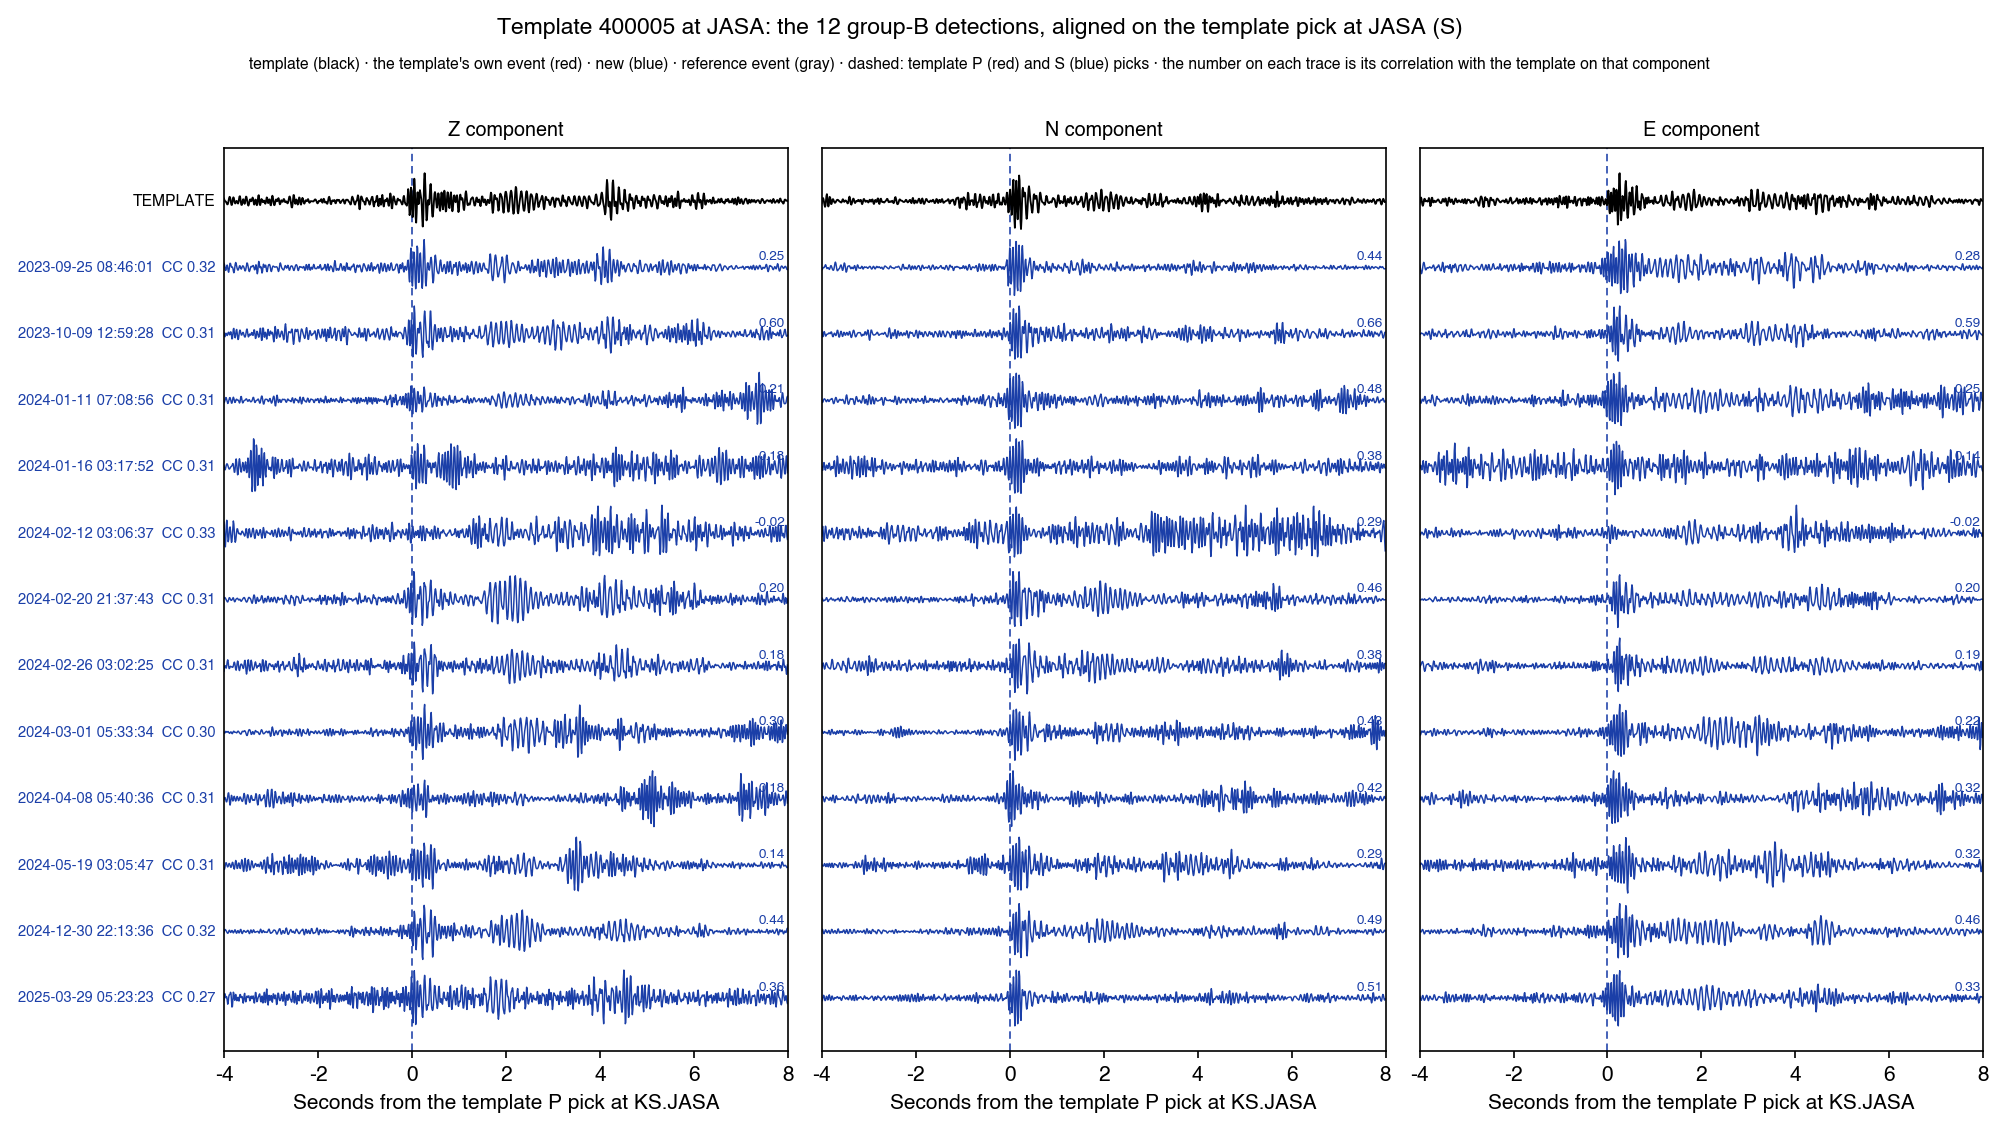

In [6]:
import station_gather as G          # imported here, not at the top: it switches matplotlib to Agg on import
png = f'{FIG}/gather_400005_JASA_groupB.png'
G.station_gather(400005, 'KS.JASA', '2023-01-01', '2025-10-01', png, title='Template 400005 at JASA: the 12 group-B detections, aligned on the template pick at JASA (S)', same_template=True, pre=4.0, span=8.0)
plt.close('all'); display(Image(png))
import matplotlib; matplotlib.use('module://matplotlib_inline.backend_inline')   # station_gather switched to Agg on import; restore inline figures

**KMA events near JASA.** KMA events within 20 km of JASA from 2023 to 2025, and whether any lies within 2 minutes of a group-B detection.

In [7]:
kma_all['dJ'] = [gps2dist_azimuth(sta.Latitude['JASA'], sta.Longitude['JASA'], a, b)[0] / 1000 for a, b in zip(kma_all.latitude, kma_all.longitude)]
qJ = kma_all[(kma_all.dJ <= 20) & (kma_all.t >= '2023-01-01') & (kma_all.t < '2025-12-31')][['t', 'latitude', 'longitude', 'depth', 'magnitude', 'dJ']].round(2)
qJ['within_2_min_of_B'] = [bool((Bt - t).abs().min() <= pd.Timedelta('2min')) for t in qJ.t]
display(qJ.reset_index(drop=True))
print(f'KMA events within 20 km of JASA: {len(qJ)}; coinciding with a group-B detection: {int(qJ.within_2_min_of_B.sum())}')

/home/msseo/miniforge3/envs/fmf/lib/python3.10/site-packages/obspy/geodetics/base.py:268: UserWarning: Catching unstable calculation on antipodes. The currently used Vincenty's Inverse formulae has known limitations for two nearly antipodal points. Install the Python module 'geographiclib' to solve this issue.
  warnings.warn(msg)


,t,latitude,longitude,depth,magnitude,dJ,within_2_min_of_B
0,2023-01-27 22:57:24,35.77,127.49,20,1.5,12.84,False
1,2023-07-29 10:07:59,35.80,127.53,6,3.5,15.89,False
2,2023-07-29 10:43:56,35.80,127.53,6,1.3,15.89,False
3,2023-10-09 20:40:18,35.81,127.53,-,1.5,17.00,False
4,2023-11-14 11:46:00,35.81,127.53,-,1.1,17.00,False
5,2023-12-06 19:42:46,35.58,127.59,19,1.7,10.62,False
6,2023-12-06 20:17:13,35.59,127.59,18,1.5,9.75,False
7,2023-12-07 00:00:50,35.58,127.60,20,1.6,11.18,False
8,2023-12-22 19:34:05,35.80,127.53,6,3.0,15.89,False
9,2023-12-22 21:14:23,35.81,127.53,-,1.4,17.00,False


KMA events within 20 km of JASA: 23; coinciding with a group-B detection: 0


## 3. Why only template 400005 caught group B

A template's network CC is the weighted mean of its channel CCs. If the signal exists only at JASA, the network CC rises only by JASA's share of the template's weight. The rest of the channels add noise, whose maximum at the chosen time is slightly positive. The table gives each template's JASA share and what a JASA-only CC of 0.75 adds to the network CC.

,template,stations,channels,JASA_S_channels,JASA_share,JASA_share_before_SIDA,added_by_JASA_cc075
0,400005,7,14,2,0.143,0.182,0.136
1,400010,13,26,2,0.115,0.130,0.098
2,400002,13,29,2,0.103,0.115,0.087
3,400008,12,29,2,0.103,0.115,0.087
4,400013,13,30,2,0.100,0.111,0.083
5,400000,15,36,2,0.083,0.091,0.068
6,400017,16,39,2,0.077,0.083,0.062
7,400006,17,39,2,0.077,0.083,0.062
8,400012,17,40,2,0.075,0.081,0.061
9,400020,18,42,2,0.071,0.077,0.058


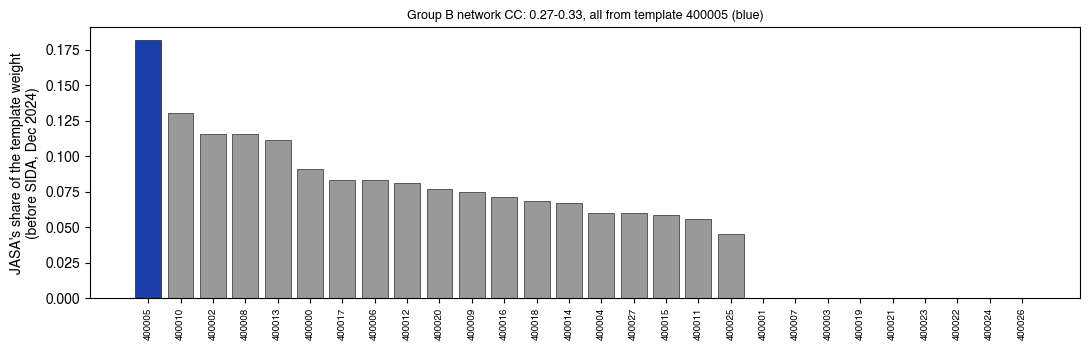

In [8]:
sh = S.load_shelly(); st_ = [str(s).split('.')[1] for s in sh['stations']]; cu = list(sh['cuspid'].astype(int)); jj = st_.index('JASA'); si_sida = st_.index('SIDA'); rows = []
for i, c in enumerate(cu):
    Pw = sh['P_weights'][i][:, 0].astype(float); Sw = sh['S_weights'][i].astype(float); wt = Pw.sum() + Sw.sum(); jw = Pw[jj] + Sw[jj].sum()
    wt_nosida = wt - (Pw[si_sida] + Sw[si_sida].sum())                       # before 2024-12: SIDA did not exist
    rows.append(dict(template=c, stations=int(((Pw > 0) | (Sw > 0).any(1)).sum()), channels=int((Pw > 0).sum() + (Sw > 0).sum()), JASA_S_channels=int((Sw[jj] > 0).sum()),
                     JASA_share=jw / wt, JASA_share_before_SIDA=jw / wt_nosida if wt_nosida else np.nan))
TW = pd.DataFrame(rows).sort_values('JASA_share', ascending=False).reset_index(drop=True); TW['added_by_JASA_cc075'] = 0.75 * TW.JASA_share_before_SIDA
display(TW.head(10).round(3))
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(range(len(TW)), TW.JASA_share_before_SIDA, color=['#1b3fa8' if c == 400005 else '0.6' for c in TW.template], edgecolor='black', lw=0.4)
ax.set_xticks(range(len(TW))); ax.set_xticklabels(TW.template, rotation=90, fontsize=7); ax.set_ylabel("JASA's share of the template weight\n(before SIDA, Dec 2024)")
ax.set_title(f'Group B network CC: {long_cat[long_cat.origin.isin(Bt)].cc.min():.2f}-{long_cat[long_cat.origin.isin(Bt)].cc.max():.2f}, all from template 400005 (blue)', fontsize=9)
plt.tight_layout(); plt.show()

## Comprehensive summary

In [9]:
b_cc = long_cat[long_cat.origin.isin(Bt)].cc
summary = pd.DataFrame([
    ('Group A size (median ratio to the ML 1.9; ML if slope 1)', '; '.join(f'{k}: {r.ratio:.3f} ({r.channels} channels), ML ~{r.ML_if_slope_1:.1f}' for k, r in AMP.iterrows())),
    ('2025 swarm: share cataloged by KMA, ratio 0.016-0.032 / 0.032-0.050 / >= 0.05', f'{rep.share.iloc[1]:.0%} / {rep.share.iloc[2]:.0%} / {rep.kma_cataloged.iloc[3:].sum() / rep.detections.iloc[3:].sum():.0%}'),
    ('KMA ML given to swarm events of ratio <= 0.04', ', '.join(f'{m}' for r, m in sorted(zip(10 ** lr_k, kma24.ML)) if r <= 0.04)),
    ('Group B: where the stacked energy rises', f'JASA {ENV["JASA"][(tax > 0) & (tax < 35)].max():.1f}x the pre-event level; IMSB {ENV["IMSB"][(tax > 0) & (tax < 35)].max():.1f}x; others <= {max(ENV[s][(tax > 0) & (tax < 35)].max() for s in ENV if s not in ("JASA", "IMSB")):.1f}x'),
    ('Group B at JASA: strongest arrival (s after detection; median) / H:V peak ratio (median)', f'{JB.strongest_arrival_s.median():.2f} / {JB.H_over_V.median():.1f}; ML 1.9 S - P at JASA {imsb_sp:.2f} s'),
    ('Group B: inter-event similarity at JASA (median, range)', f'{np.nanmedian(M[iu]):.2f} ({np.nanmin(M[iu]):.2f}-{np.nanmax(M[iu]):.2f})'),
    ('Group B: local time (KST)', ', '.join(sorted(JB.KST))),
    ('KMA events within 20 km of JASA, 2023-2025 / coinciding with group B', f'{len(qJ)} / {int(qJ.within_2_min_of_B.sum())}'),
    ('Template 400005: JASA share of weight (before SIDA) / largest of the other templates', f'{TW.set_index("template").JASA_share_before_SIDA[400005]:.3f} / {TW[TW.template != 400005].JASA_share_before_SIDA.max():.3f}; group-B network CC {b_cc.min():.2f}-{b_cc.max():.2f}'),
], columns=['quantity', 'value'])
display(summary)

,quantity,value
0,Group A size (median ratio to the ML 1.9; ML i...,"A1: 0.025 (10 channels), ML ~0.3; A2: 0.043 (1..."
1,"2025 swarm: share cataloged by KMA, ratio 0.01...",16% / 43% / 100%
2,KMA ML given to swarm events of ratio <= 0.04,"1.4, 1.3, 1.4, 1.7, 1.3"
3,Group B: where the stacked energy rises,JASA 4.6x the pre-event level; IMSB 2.0x; othe...
4,Group B at JASA: strongest arrival (s after de...,9.35 / 1.3; ML 1.9 S - P at JASA 3.15 s
5,Group B: inter-event similarity at JASA (media...,0.39 (0.25-0.76)
6,Group B: local time (KST),"06:37, 07:13, 12:02, 12:05, 12:06, 12:17, 14:2..."
7,"KMA events within 20 km of JASA, 2023-2025 / c...",23 / 0
8,Template 400005: JASA share of weight (before ...,0.182 / 0.130; group-B network CC 0.27-0.33
